In [1]:
import numpy as np
import epde.interface.interface as epde_alg
import torch
from epde.interface.prepared_tokens import CustomTokens, CacheStoredTokens, ExternalDerivativesTokens, TrigonometricTokens
import itertools
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import re

import matplotlib as mpl
mpl.rc('text', usetex=False)

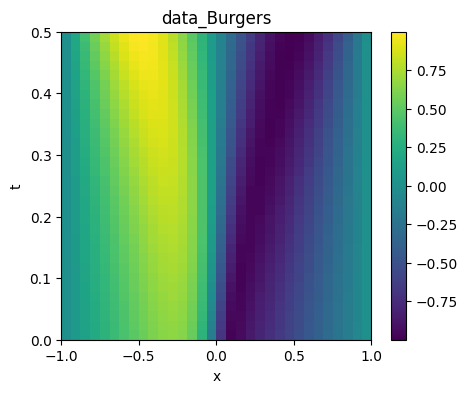

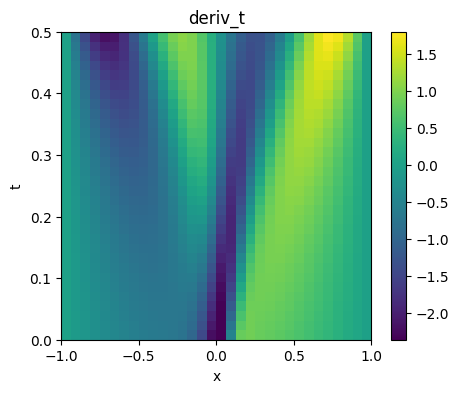

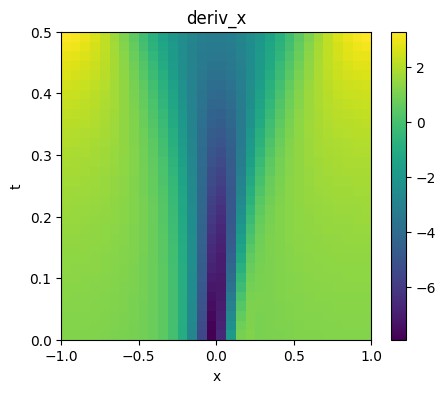

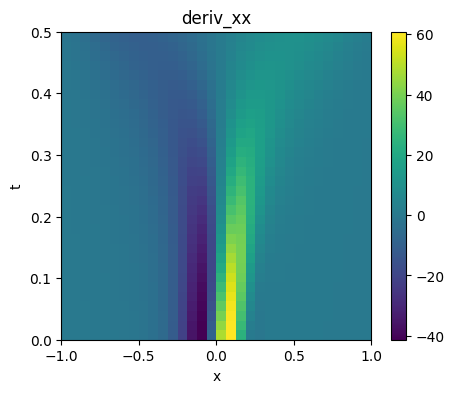

In [2]:
x = np.linspace(-1, 1, 32)  
t = np.linspace(0, 0.5, 32)
data = np.load('data_Burgers_noise0.npy')  
deriv_x = np.load('Burgers_Gradient_x_noise0.npy')
deriv_xx = np.load('Burgers_Gradient_xx_noise0.npy')
deriv_t = np.load('Burgers_Gradient_t_noise0.npy')

boundary = 5
dimensionality = data.ndim - 1   
grids = np.meshgrid(t, x, indexing = 'ij')    

plt.figure(figsize=(5, 4))
plt.imshow(data, aspect='auto', extent=[np.min(x), np.max(x),np.min(t), np.max(t)], cmap='viridis')
plt.colorbar()
plt.title('data_Burgers')
plt.xlabel('x')
plt.ylabel('t')
plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(deriv_t, aspect='auto', extent=[np.min(x), np.max(x),np.min(t), np.max(t)], cmap='viridis')
plt.colorbar()
plt.title('deriv_t')
plt.xlabel('x')
plt.ylabel('t')
plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(deriv_x, aspect='auto', extent=[np.min(x), np.max(x),np.min(t), np.max(t)], cmap='viridis')
plt.colorbar()
plt.title('deriv_x')
plt.xlabel('x')
plt.ylabel('t')
plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(deriv_xx, aspect='auto', extent=[np.min(x), np.max(x),np.min(t), np.max(t)], cmap='viridis')
plt.colorbar()
plt.title('deriv_xx')
plt.xlabel('x')
plt.ylabel('t')
plt.show()

In [3]:
multiobjective_mode = True
epde_search_obj = epde_alg.EpdeSearch(multiobjective_mode=multiobjective_mode, use_solver = False, boundary = 5,
                                        coordinate_tensors = grids)

epde_search_obj.set_preprocessor(default_preprocessor_type='poly', # use_smoothing = True
                                     preprocessor_kwargs={'use_smoothing' : False})    
popsize = 7
if multiobjective_mode:
    epde_search_obj.set_moeadd_params(population_size = popsize, 
                                        training_epochs=80)
else:
    epde_search_obj.set_singleobjective_params(population_size = popsize, 
                                                training_epochs=80)

setting builder with <epde.optimizers.builder.StrategyBuilder object at 0x00000214D9BFF0E0>
setting builder with <epde.optimizers.builder.StrategyBuilder object at 0x00000214D9BFF0E0>


In [4]:
print(grids[0].shape)
print(grids[1].shape)
print(deriv_x.shape)
print(data.shape)

(32, 32)
(32, 32)
(32, 32)
(32, 32)


In [5]:
#Burgers
factors_max_number = {'factors_num' : [1, 2], 'probas' : [0.5, 0.5]}

derivs = np.stack((deriv_t.reshape(-1),
                   deriv_x.reshape(-1),
                   deriv_xx.reshape(-1)), axis=1)


print('data.shape =', torch.tensor(data).shape)
print('derivs.shape = ', torch.tensor(derivs).shape)
opt_val = 1e-8
bounds = (1e-8, 1e-2) if multiobjective_mode else (opt_val, opt_val) 
 
results = []

for i in range(50):
    epde_search_obj.fit(data=data, variable_names=['u',], max_deriv_order=(1, 2), derivs = [derivs,],
                        equation_terms_max_number=8, data_fun_pow=2, 
                        #additional_tokens=[custom_grid_tokens],
                        equation_factors_max_number=factors_max_number,
                        eq_sparsity_interval=bounds)
    text_eq = epde_search_obj.equations(only_print=False, only_str=True, num=1)
    results.extend(text_eq)  
results = list(itertools.chain.from_iterable(results))
print(results)


data.shape = torch.Size([32, 32])
derivs.shape =  torch.Size([1024, 3])
Deriv orders after definition [[0], [1], [1, 1]]
initial_shape (32, 32) derivs_tensor.shape (1024, 3)
Size of linked labels is 4
The cardinality of defined token pool is [1 3]
Among them, the pool contains [1 3]
self.vars_demand_equation {'u'}
Creating new equation, sparsity value [1.14183249e-08]
New solution accepted, confirmed 1/7 solutions.
Creating new equation, sparsity value [2.60658831e-06]


TypeError: 'ChromosomeEqIterator' object is not iterable